В данном ноутбуке расчитываются Z спреды по облигациям

In [20]:
import pandas as pd
from scipy.optimize import brentq
import numpy as np
import matplotlib.pyplot as plt

In [5]:
risk_free = pd.read_csv('../risk_free_rates/risk_free_USA.csv', skiprows=9)
risk_free.head(2)

,Date,BETA0,BETA1,BETA2,BETA3,SVEN1F01,SVEN1F04,SVEN1F09,SVENF01,SVENF02,...,SVENY23,SVENY24,SVENY25,SVENY26,SVENY27,SVENY28,SVENY29,SVENY30,TAU1,TAU2
0,1961-06-14,3.917606,-1.277955,-1.949397,0.0,3.8067,3.9562,NaN,3.5492,3.8825,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.339218,-999.99
1,1961-06-15,3.978498,-1.257404,-2.247617,0.0,3.8694,4.0183,NaN,3.5997,3.9460,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.325775,-999.99


In [7]:
bond = pd.read_csv('../Bonds/097023AS4= Overview (1).csv')
bond.head(2)

,Date,Price,Open,High,Low,Change %
0,31/03/2025,107.124,107.124,107.124,107.124,1.19%
1,27/03/2025,105.865,105.865,105.865,105.865,-0.34%


In [24]:
def get_z_spread(risk_free, bond, maturity, coupon, frequency=None, coupon_dates=None):
    risk_free = risk_free.copy()
    bond = bond.copy()

    risk_free["Date"] = pd.to_datetime(risk_free["Date"])
    bond["Date"] = pd.to_datetime(bond["Date"])
    maturity = pd.Timestamp(maturity)

    df = bond.merge(
        risk_free[["Date", "BETA0", "BETA1", "BETA2", "BETA3", "TAU1", "TAU2"]],
        on="Date"
    )

    months = 12 // frequency
    payment = coupon / frequency

    if coupon_dates is None:
        dates = pd.DatetimeIndex([
            maturity - pd.DateOffset(months=months*k)
            for k in range(200)
        ]).sort_values()
    else:
        dates = pd.DatetimeIndex(pd.to_datetime(coupon_dates)).sort_values()

    out = []

    for _, x in df.iterrows():
        future_dates = dates[dates > x.Date]
        if len(future_dates) == 0:
            continue

        T = (future_dates - x.Date).days / 365.25

        r = (
            x.BETA0
            + x.BETA1 * (1 - np.exp(-T/x.TAU1)) / (T/x.TAU1)
            + x.BETA2 * ((1 - np.exp(-T/x.TAU1))/(T/x.TAU1) - np.exp(-T/x.TAU1))
            + x.BETA3 * ((1 - np.exp(-T/x.TAU2))/(T/x.TAU2) - np.exp(-T/x.TAU2))
        ) / 100

        cf = np.full(len(T), payment)
        cf[-1] += 100

        prev = dates[dates <= x.Date][-1]
        next_date = future_dates[0]

        dirty = x.Price + payment * (x.Date - prev).days / (next_date - prev).days

        try:
            z = brentq(
                lambda z: np.sum(cf * np.exp(-(r + z) * T)) - dirty,
                -0.1, 0.5
            )
            out.append([x.Date, z * 10000, r[-1] * 100, (maturity - x.Date).days])
        except ValueError:
            continue

    return pd.DataFrame(out, columns=["Date", "Z", "rf" ,"Days_to_maturity"])

In [25]:
z_spread = get_z_spread(
    risk_free,
    bond,
    maturity="2038-02-15",
    coupon=6.625,
    frequency=2
)

/var/folders/43/y646xgv56z72xq7sm281s4zr0000gn/T/ipykernel_71861/2995688724.py:6: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  bond["Date"] = pd.to_datetime(bond["Date"])


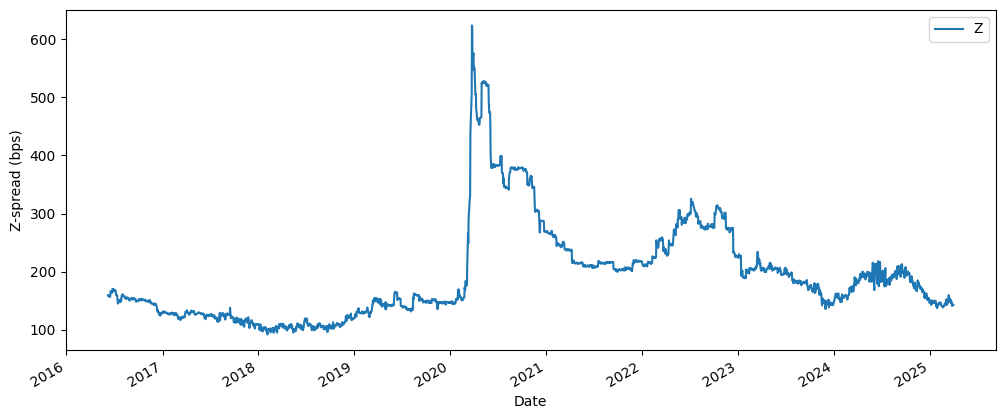

In [26]:
z_spread.sort_values("Date").plot(x="Date", y="Z", figsize=(12, 5))
plt.ylabel("Z-spread (bps)")
plt.show()

In [27]:
z_spread.to_csv('Z_BA.csv')